# Homework 1: Hypothesis testing

This assignment has 4 parts. Each part is graded as listed in its heading.

## Homework 1.1 (24 points)

**Learning objectives:**

In this assignment, we will get started using Python in a Google Colab notebook.  We will explore how to:

*   load data
*   manipulate arrays
*   visualize probability density functions (PDFs) and cumulative distribution functions (CDFs)
*   z-score data

---
### Part 1 (2 points)
*   First, load the package 'numpy'.  

Numpy is a widely used python package that contains a large number of mathematical functions that we will use for various analyses throughout the course.  It also adds support for multidimensional arrays that we will store data in.  Give numpy the alias 'np' for brevity.  To do this, type:

`import numpy as np`

For those who are familiar with Matlab but just getting started with Python, here is a useful cheat sheet:

https://numpy.org/doc/stable/user/numpy-for-matlab-users.html

In [ ]:
# Your code here


---
### Part 2 (2 points)
*   Next, load `matplotlib.pyplot` and call it `plt` for brevity.  

`pyplot` is a part of the larger `matplotlib` package, which contains powerful functionality for plotting data using similar synatx to Matlab.  Thus, `pyplot` is a subpackage of` matplotlib`.

*   Similarly, load in `scipy.stats` and call it `stats`.

In [ ]:
# Your code here


---
### Part 3 (2 points)
*   Load a dataset that includes height and weight data from 25,000 18-year-olds.  These data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework1/SOCR-HeightWeight.csv

To do this, use the `genfromtxt` function in numpy (i.e. `np.genfromtxt`) to load the data directly from this URL into a variable called `HeightsAndWeights`.  Since this is a .csv file, you will need to set the delimiter to ',' (a comma in single quotes).  The first row in the file contains column labels.  You can use the option `skip_header=1` to skip the first line and only read the numerical data.  

You should be able to mouse over the function name in your code to see more information about it.  Select 'open in tab' to see more information about `genfromtxt` or view the help page online https://numpy.org/doc/stable/reference/generated/numpy.genfromtxt.html

You can get additional information about other fuctions in a similar manner.

In [ ]:
# Your code here


---
### Part 4 (2 points)
Make some easy-to-use variables.  

*   Assign the height data (in the second column of HeightsAndWeights) to a variable called `heights`.  Similarly, assign the weight data (the third column) to a variable called `weights`.

*   Calculate the mean and standard deviation of the heights data and assign these values variables called `meanHeight` and `stdHeight` using the numpy functions `mean` and `std`.

🚩 **Common mistake:** Python counts from 0, so the "second column" of an array is index 1, not 2. Indexing with the wrong number runs without error but silently gives you the wrong variable (or fails at the last column), so check what you extracted, for example by looking at its first few values.


In [ ]:
# Your code here


---
### Part 5 (2 points)
Next, lets plot some things that allow us to get a sense of our data.  


*   Use the `subplots` function in `matplotlib` to create a 1x3 row of three axes like this:

`fig, axs = plt.subplots(1, 3)`

Here, `axs` is a vector of axes handles.  A handle is an identifier for a graphics object that can be used to refer to and modify that object. If you click the `{x} `icon on the left hand side of your notebook, you will see all of the variables in your workspace.  You should see, for example that this command created an n-dimensional array (ndarray)  called `axs` with three elements.

*   Plot a histogram of the height data in the first subplot.  Make a histogram with 50 bins.

`axs[0].hist(heights, bins = 50)`

*   Plot a histgram of the weight data in the second subplot.  Again, use 50 bins.

*   Make a scatter plot (using `axs[].plot` instead of `axs[].hist`) with the height data on the x-axis and the weight data on the y-axis in the third subplot.  Show each data point as a black dot and set the alpha (transparency) of the points to 0.1.

---

In all cases, label your axes appropriately.  You can use the following commands to size your plots nicely:

```
fig.set_size_inches(16, 4)
plt.tight_layout()
```

You can also use this command to change the fontsize associated with axes you create (must be run before you call plot commands).

`plt.rcParams.update({'font.size': 16})`

Your plots should look like the ones below:

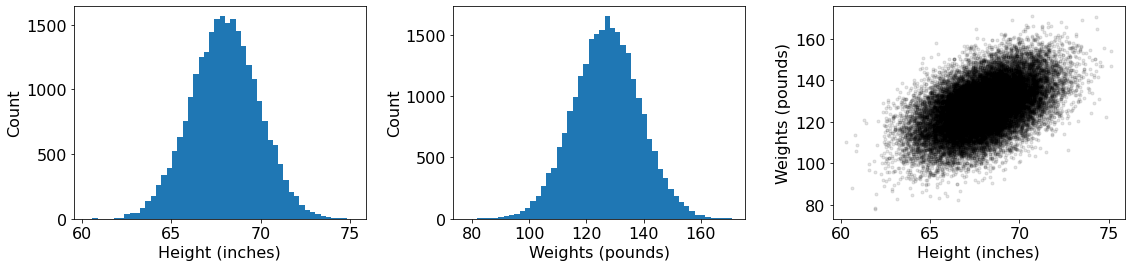

In [ ]:
# Your code here


---
### Part 6 (2 points)
Are heights normally distributed?  No need for statistical tests yet, lets just take a look by eye.

*   Use `plt.hist` to make a histogram of the height data just as you did above.  This time, apply the option `density=true`, which normalizes bin counts so that the sum of all bins equals 1.

*   On the same plot, display the probability density function (PDF) of a normal distribution that has the same mean and standard deviation as your data. We'll do it two ways.

**Method 1:** First, we will calculate the PDF based on the familiar equation for a normal distribution.

$ P(x,\mu,\sigma) = \frac{1}{\sigma\sqrt{2\pi}} e^{(-\frac{{(x - \mu)}^{2}}{2\sigma^{2}})}$

> **Step 1:** Create a vector of heights at which we will calculate probabilities.  Use the numpy function `arrange` to create a vector called `xdata` with a minimum value of `meanHeight`-5, a maximum value of `meanHeight`+5, and increments of 0.1.

> **Step 2:** Find the probability density at each point using the equation above.  You may need to use numpy functions such as `np.sqrt`, `np.pi`, and `np.exp`.

> **Step 3:** Plot the normal pdf as a black line with a width of 2.

**Method 2:** Second, we will find the probability density function using built in functionality of `scipy.stats`.  

> **Step 1:** Create a normal random variable called `heightDist` with the same mean and standard deviation as your data using `stats.norm`.

> **Step 2:**Create a variable that contains the probability densities at each point in `xdata` by calling `heightDist.pdf` with `xdata` as the argument.

> **Step 3:** Plot the normal pdf determined using the stats package as a red dotted line with width 3.

*    Add a legend to this plot that labels the curves determined using **Method 1** and **Method 2**.

🚩 **Common mistake:** `density=True` makes the bar *areas* (height times bin width) sum to 1, not the bar heights. If you leave it off, the histogram is in raw counts and a PDF drawn on the same axes will look flat near zero.

See the lecture notes on [The normal distribution](https://depasquale-lab.github.io/BE559/lectures/Lecture1.1.html#the-normal-distribution) for the normal PDF.


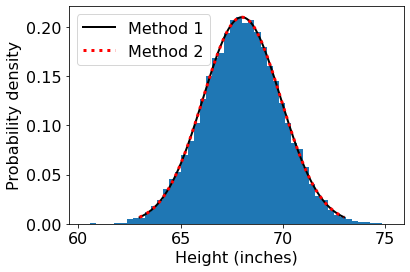

In [ ]:
# Your code here


It seems these data are normally distributed!

---
### Part 7 (2 points)
Now, suppose you meet someone named Bob. Bob is 5'4".  What is the chance that Bob is 18 years old (i.e. that this value was drawn from the same distribution) based solely on their height?

First, lets see where Bob falls in the normal distribution.

*   Use either method above to plot the pdf of the normal distribution, just as you did above.

*   Calculate the probability density at 5'4" (64 inches) using the normal equation or `scipy.stats`.

*   Plot the probability density at 64 inches on the same axes as a blue dot with `markersize` set to 20.

🚩 **Common mistake:** Heights in this dataset are in inches, so 5'4" is 5 x 12 + 4 inches, not 5.4. Entering the wrong number runs fine but places Bob at the wrong spot on the distribution.


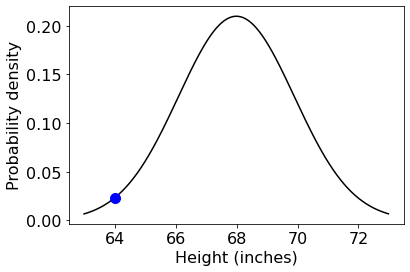

In [ ]:
# Your code here


---
### Part 8 (2 points)
Lets calculate how far Bob's height is from the mean height in our dataset

*   Calculate the difference between Bob's height and `meanHeight` and assign this value to a variable called `deltaHeight`.

*   Display the answer in plain text using a strategy like this:

`print("Individual is " + str(deltaHeight) + " shorter than average")`

or, if you want to format the output better...

`print(f'Individual is {deltaHeight:.2f} inches shorter than average')`

In [ ]:
# Your code here


Individual is 3.9931135967999865 shorter than average
Individual is 3.99 inches shorter than average


---
### Part 9 (2 points)
Is this a lot?  It is more informative to think about this in terms of the width of the distribution - the standard deviation.  

How far is Bob's height from the mean of the distribution in terms of standard deviations?

*   Divide `deltaHeight` by the standard deviation of the height measurements, `stdHeight`.

This is the z-score of Bob's height relative to the normal distribution you determined.

$ z = \frac{(x - \mu)}{\sigma} $

*   Report the z-score of Bob's height using a `print` statement and appropriate text.

See the lecture notes on [The Z-score](https://depasquale-lab.github.io/BE559/lectures/Lecture1.2.html#the-z-score) for how z-scores are defined and used.


In [ ]:
# Your code here


z score: x.xx


---
### Part 10 (2 points)
If we apply the same math to our original `heights` data, the distribution now looks like a normal distribution with mean 0 and standard deviation 1.  This is the **standard normal distribution**.

*   Plot a histogram of the full z-scored `heights` data.

*   Plot the PDF of the standard normal distribution using **Method 2** from **Part 6** as a black line.  You'll need to create a standard normal random variable object like this:

   `zDist = stats.norm(0, 1)`

   and then find its PDF using code such as this:

   `zPDF = zDist.pdf(x)`

   where x now spans the interval from -4 to 4.


*   Plot the z-scored measurement of Bob's height on the same axis as a red dot of size 20.


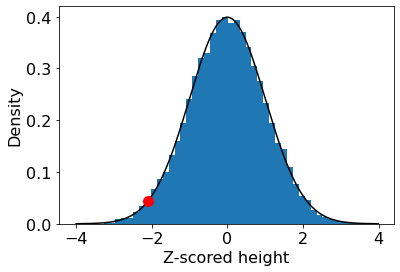

In [ ]:
# Your code here


---
### Part 11 (2 points)

OK, now we are getting close to an answer!

Next, lets visualize the cumulative distribution function (CDF) of the standard normal.  This is:

$ P(X<x) = {\frac{1}{\sqrt {2\pi}}} \int _{-\infty }^{x}e^{-x^{2}/2} dx $

We'll use `scipy.stats` to calculate this integral for us.

*   You've already created a standard normal random variable, `zDist`, which we'll use.  Find the CDF of the standard normal and plot just as you did for the PDF in **part 10**,  but using `Zdist.cdf` instead of `zDist.pdf`.

*   Plot the PDF on the same axes in blue with `alpha=0.2` for reference

*   On the same axes, plot the cumulative probability at the location of Bob's z-scored height as a red dot.

See the lecture notes on [PDFs and CDFs](https://depasquale-lab.github.io/BE559/lectures/Lecture1.1.html#pdfs-and-cdfs) for the relationship between a PDF and a CDF.


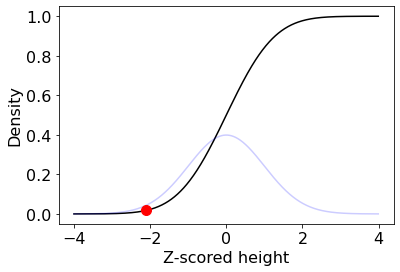

In [ ]:
# Your code here


---
### Part 12 (2 points)

Now, we will find the likelihood of Bob's height being 64 inches or less under the assumption that Bob's height was drawn randomly from a population of 18 year olds.

We'll do this two ways.

**Method 1:** Find the probability using `scipy.stats`.

*   Calculate the area under the standard normal pdf to the left of our data point (Bob's height, z-scored).  This is the value of the cdf at the same point point.  Use `scipy.stats` to find this value and print it.

**Method 2:** Calculate the proportion of data points in our `heights` dataset that are 64 inches or less.

In [ ]:
# Your code here


There is a = x.x % chance of randomly choosing a height 64 inches or lower using Method 1
There is a = x.x % chance of randomly choosing a height 64 inches or lower using Method 2


## Homework 1.2 (34 points)

**Learning objectives:**

In this assignment, we will refine our python skills and delve into hypothesis testing.  We will explore:

*   Sampling
*   Sample statistics and their distributions
*   The t distribution and t-test

**NOTE:**  Include axis labels in all plots!

---
### Part 1 (2 points)

Load the same libraries that we used in *Homework 1.1*.

*   `numpy` (as `np`)

*   `matplotlib.pyplot` (as `plt`)

*   `scipy.stats` (as `stats`)

Now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 2 (2 points)

*   Load the same height and weight data taken from 25,000 18-year-olds as in *Homework 1.1*.  These data are stored in a .csv (comma separated values) file at the following URL:

   https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework1/SOCR-HeightWeight.csv

   Use the `genfromtxt` function in numpy (i.e. `np.genfromtxt`) to load the data directly from this URL into a variable called `HeightsAndWeights`.  

*   Make an easy-to-use variable called `heights` form the second column of `HeightsAndWeights`

In [ ]:
# Your code here


---
### Part 3 (2 points)

Suppose we measure the heights of three students taking BE 700 to be 70.5", 72", and 68".

*   Create a numpy array containing these values called `classHeights`.
*   Print the array



In [ ]:
# Your code here


[70.5 72.  68. ]


---
### Part 4 (2 points)

Visualize our measurements (`classHeights`) and the distribution of the reference data (`heights`) on the same axis.

*   Create a normal random variable with the same mean and standard deviation as the `heights` dataset and call it `heightDist`.

*   Plot the probability density function (PDF) of `heightDist` over the relevant range of heights.

*   On the same axes, plot a histogram of `classHeights`.  Set  `density=True` and `alpha=0.2`.  For this histogram, set the bin edges explicitly as `bins=np.arange(60, 74)` so that each bin has a width of 1 inch

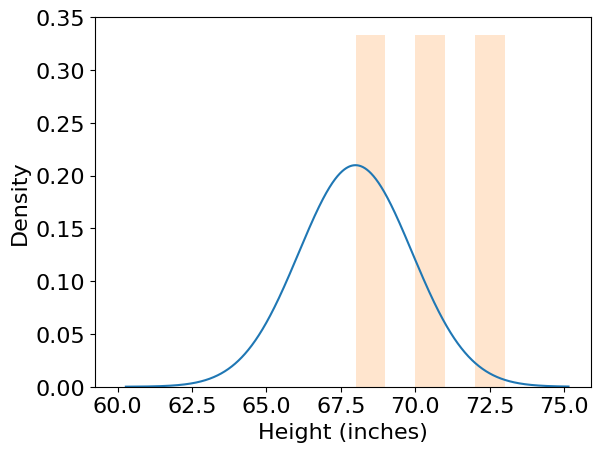

In [ ]:
# Your code here


---
##Step 5 (2 points)

Calculate some descriptive statistics and print them.

*   Mean value of `heights`

*   Mean value of `classheights`

*   Standard deviation of values in `heights`

*   Standard deviation of values in `classHeights`

Display them as below:

In [ ]:
print(f'Mean height in dataset = xx.xx inches')
print(f'Mean height in class = xx.xx inches')
print(" ")

print(f'Standard deviation of heights in dataset = x.xx inches')
print(f'Standard deviation of heights in class = x.xx inches')

Mean height in dataset = xx.xx inches
Mean height in class = xx.xx inches
 
Standard deviation of heights in dataset = x.xx inches
Standard deviation of heights in class = x.xx inches


---
### Part 6 (2 points)

*   z-score `classHeights` using the mean and standard deviation of `heights`.  Call this variable `ZclassHeights`.
*   Plot a histogram of `ZclassHeights`.
*   Overlay the PDF of the standard normal distribution. For this you can use `stats.norm.pdf`

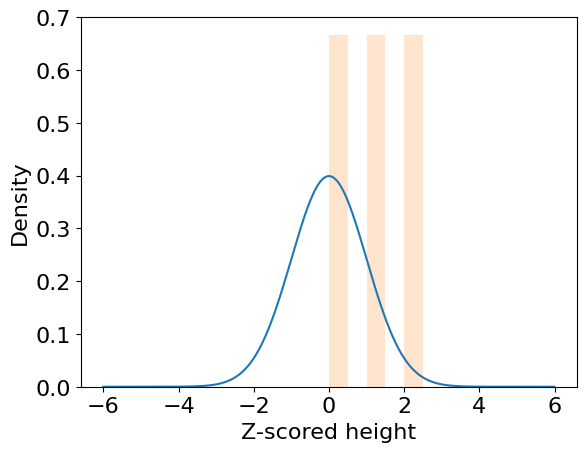

In [ ]:
# Your code here


---
### Part 7 (2 points)

Let's start to do some more rigorous comparisons of our sample data (`classHeights`) and our reference dataset (`heights`).  

First, consider the mean of our sample data.  

*   Calculate the z-score of our sample data's mean and print it.  

In [ ]:
print(f'Z-scored mean height = x.xx')

Z-scored mean height = x.xx


The mean of these measurements is well within the reference distribution of heights.

---
### Part 8 (2 points)

Where does the z-score of the sample mean fall within the standard normal distribution?

*   Plot the CDF of the standard normal distribution and display the location of the sample mean as a red dot with `markersize=20`. In order to get the CDF you can use `stats.norm.cdf`

*   Calculate the value of the CDF at the location of the sample mean and display this value.  
*   What percent of the standard normal distribution is as large or larger than the sample mean?  Print this value.

xx.xx% of the standard normal distribution lies to the right of the sample mean


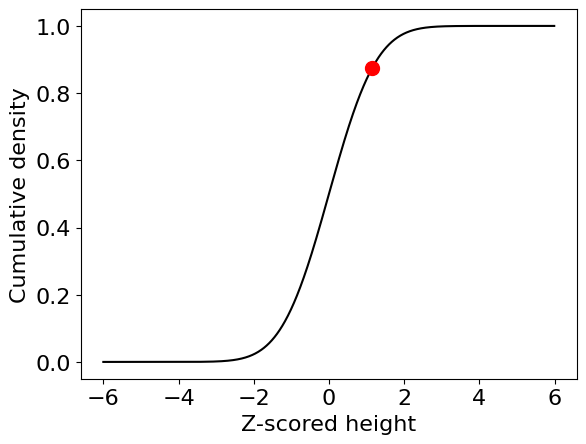

In [ ]:
# Your code here


Does this tell us the likelihood of drawing a sample from the reference dataset of 18-year-old heights that has this mean?  

NO!  

Why?  The distribution of the `heights` data is different than the distribution of the means of random samples drawn from those data.

The mean of our sample is our **sample statistic**.  So what is the distribution of this sample statistic, if not the distribution from which we drew the samples?  Let's try to find out!

First, we'll randomly select samples from `heights` with the same number of elements as `classHeights` and find out empirically what the distribution of the sample means should look like.

*   Draw a random sample from `heights` with the same number of elements as `classHeights` and find the mean. You can draw random samples from an array using `np.random.choice`.  
*   Calculate the mean of this random sample and z-score it.

In [ ]:
print(f'Mean of random sample = xx.xx inches')
print(f'Z-scored mean = x.xx')

Mean of random sample = xx.xx inches
Z-scored mean = x.xx


---
### Part 9 (2 points)

OK, now that we know how to draw random samples, we'll use this to gain some intuition about the values that we expect sample means to take.

*   Repeat this calculation 5000 times using a `for` loop and store the random sample means as a numpy array.

*   Plot a histogram of the random sample means.

*   Overlay the PDF of the normal distribution with the mean and standard deviation of `heights`.

See the lecture notes on [Central Limit Theorem](https://depasquale-lab.github.io/BE559/lectures/Lecture1.2.html#central-limit-theorem) for the distribution of sample means.


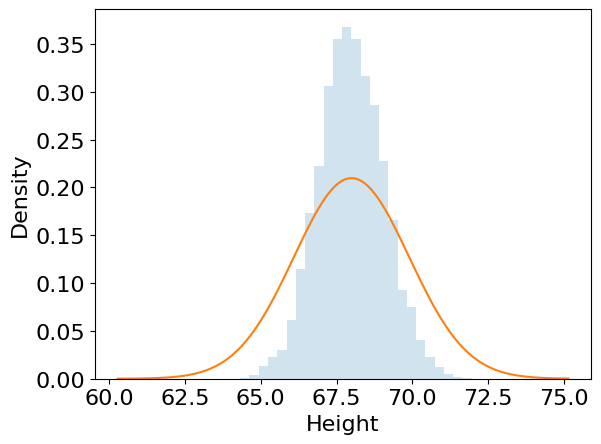

In [ ]:
# Your code here


These look different!   

This is the **central limit theorem** in action!  

To recall, if we calculate the mean of a sample of random variables

$\displaystyle {\bar {X}}_{n}\equiv {\frac {X_{1}+\cdots +X_{n}}{n}}$

the distribution of sample means is a normal distribution with mean, ${\mu}$, and standard deviation, ${\frac{\sigma}{\sqrt {n}}}$.  Here $ n $ is the size of the random sample and ${\sigma}$ is the standard deviation of the population.

The width of this distribution is the standard error of the measurement of the mean, ${\frac{\sigma}{\sqrt {n}}}$, rather than the standard deviation of the population,
${\sigma}$.

---
### Part 10 (2 points)

Let's see if this prediction holds true.

*   Plot the histogram of sample means.

*   Overlay the PDF of a normal distribution with the mean, ${\mu}$, and standard deviation, $\sigma$, of the `heights` data, as above.

*   Finally, overlay the PDF of a normal distribution with mean, ${\mu}$, and standard deviation , ${\frac{\sigma}{\sqrt {n}}}$.


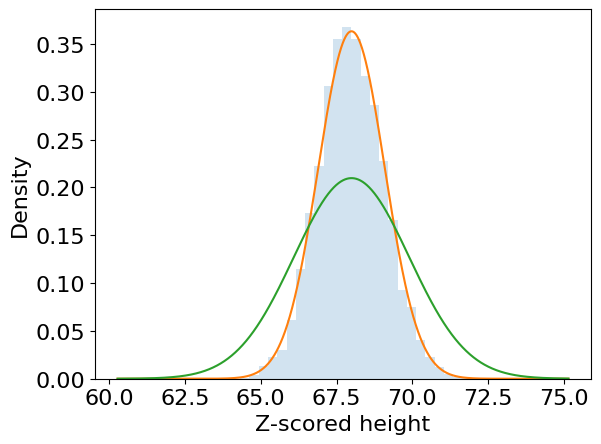

In [ ]:
# Your code here


---
### Part 11 (2 points)

OK!  Let's re-examine where our measurement falls in this new distribution - the distribution of means of random samples of this size (N=3) drawn from the `heights` dataset.

*   Plot the PDF of the distribution you found in **Part 10**.

*   Now plot where the mean of `classHeights` falls in this distribution as a red dot.

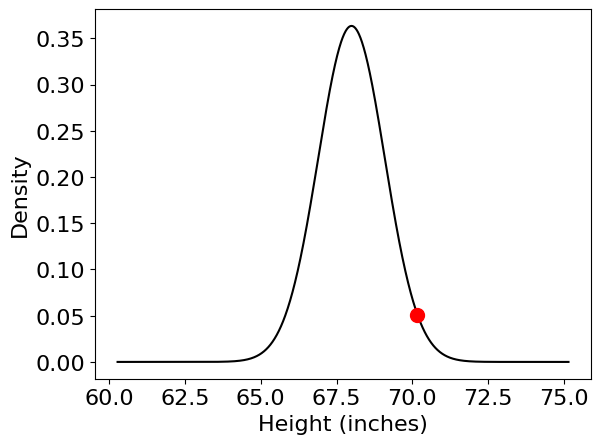

In [ ]:
# Your code here


---
### Part 12 (2 points)

Now, calculate the probability that the mean of classHeights is as large or larger than the measured value.  Do this two ways:

*   **Method 1 (Monte Carlo):** Directly find the proportion of random sample means  larger than the class sample mean.  This is the estimated probability of drawing a sample from `heights` with a mean as large (or larger) than the mean of `classHeights`.

*   **Method 2 (analytical):** Use the cdf of the normal distribution with the same mean as `heights` and standard deviation equal to ${\frac{\sigma}{\sqrt {n}}}$ (the predicted distribution of sample means) to determine the probability of measuring a set of class heights with this mean.



In [ ]:
print(f'Probability (Monte Carlo) = x.xx% chance')
print(f'Probability (analytical) = x.xx% chance')

Probability (Monte Carlo) = x.xx% chance
Probability (analytical) = x.xx% chance


These probabilities may not be exactly th same, but if you increased the number of random samples drawn in **Part 9**, then these values would eventually converge.

---
### Part 13 (2 points)

This is great!  But we still haven't *quite* gotten to where we need to be.

Why? In this case, we are comparing against a reference datset with a huge number of measurements, and we can estimate the population mean and standard deviation from these data with very high accuracy.  But this is not usually the case!

Instead, lets consider a slightly different scenario:

**Problem:**  What is the probability that our classHeights data were drawn from a normal distribution with mean of 67.99 (the mean of `heights`), when all we have is our measurements?

Importantly, now we do not know the expected standard deviation of a sample of size N, because we don't know the standard deviation of values in the the whole population.  All we have is the standard deviation of our measurements, which we could use as an imperfect estimate of the standard deviation of the population.

This is where the **'t' distribution** and **t tests** come in.  We've seen that the z statistic:

${\displaystyle {z = \frac {{\bar {X}}-\mu }{\sigma /{\sqrt {n}}}}}$

follows the standard normal distribution.  But we often don't know $\sigma$.  Instead, we can calculate a related statistic, the **t statistic:**

${\displaystyle {t = \frac {{\bar {X}}-\mu }{S/{\sqrt {n}}}}}$

Where S is the **sample** standard deviation, which we can calculate directly from our sample data (`classHeights`).  The PDF of the t distribution is given by:

$f(t)={\frac {\Gamma ({\frac {\nu +1}{2}})}{{\sqrt {\nu \pi }}\,\Gamma ({\frac {\nu }{2}})}}\left(1+{\frac {t^{2}}{\nu }}\right)^{-(\nu +1)/2} $

We won't derive this equation, but it is important to point out that it is parameterized by a single number, the degrees of freedom of the distribution, $\nu$.

That is, the t distribution has a shape that depends only on this parameter.  

Here, the degrees of freedom is typically equal to the number of observations minus one $(n-1)$, for reasons that we will discuss in class.

On the same axes, plot:
*   The PDF of the standard normal distribution
*   The PDF of the t distribution (`stats.t`) with the appropriate dof for the `classHeights` data
*   Include a legend.

In both cases, use `scipy.stats` to find the PDF.


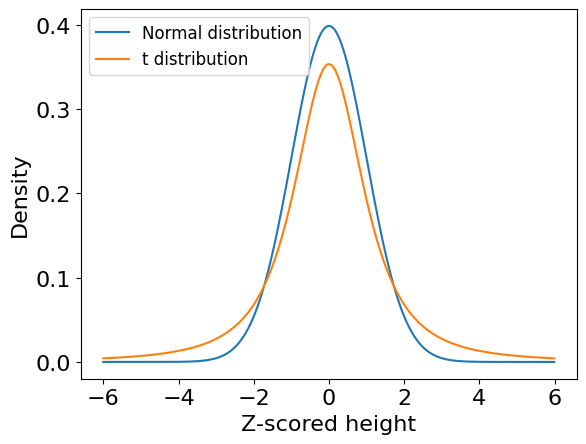

In [ ]:
# Your code here


---
### Part 14 (2 points)
Examine the shape of the t distribution for different degrees of freedom compared to the standard normal distribution

*   Use `scipy.stats` to generate t distributions with dof= 2, 4, 8, 16, 32.
*   Plot the PDFs on the same axes and label them.
*   On the same axes, plot the standard normal distribution as a black line with `linewidth=2`

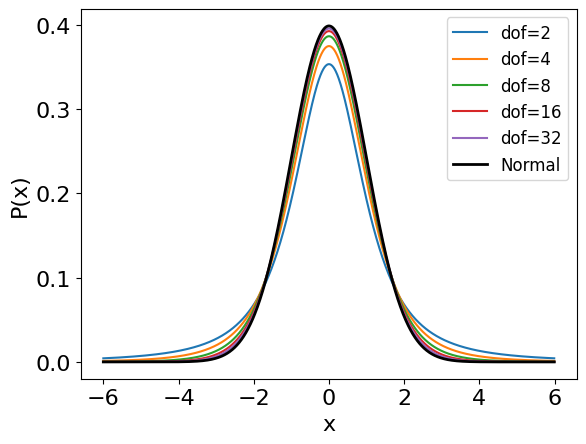

In [ ]:
# Your code here


You should see that the t distribution coverges to the stanadard normal distribution as the number of observations (degrees of freedom) increases as the sample standard deviation becomes a better and better estimate of the population standard deviation.

---
### Part 15 (2 points)
*   Repeat **Part 9**, but instead of calculating the z statistic for each random sample, compute the t statistic.  To calculate S appropriately, you will need to use `np.std` and set the option `ddof=1` (essentially dividing by `n-1` instead of `n`). This will give you an unbiased estimate of the population standard deviation.
*   Plot a histogram of these t statistics.
*   Overlay the standard normal distribution and the t distribution with the appropriate degrees of freedom.

🚩 **Common mistake:** `np.std` divides by `n` by default (`ddof=0`). For a t statistic computed from a small sample you need `ddof=1`; forgetting it runs without error but makes S too small and every t statistic too large.

See the lecture notes on [t statistic](https://depasquale-lab.github.io/BE559/lectures/Lecture1.4.html#t-statistic) for how the t statistic is computed.


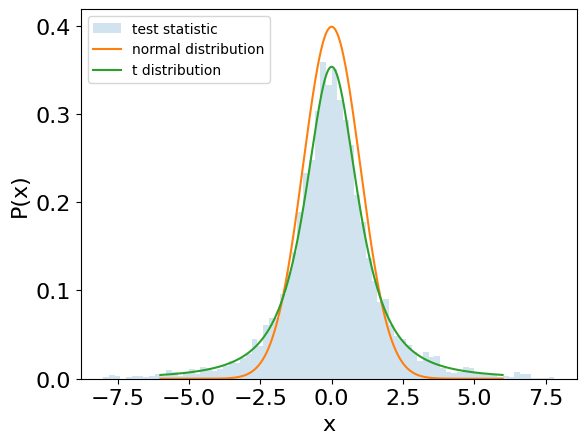

In [ ]:
# Your code here


Great!  Now you should see that the histogram of t statistics you calculated by randomly sampling `heights` matches the t distribution.

The t distribution and normal distribution look somewhat similar, even when the degrees of freedom is low, but the t distribution has much 'heavier' tails - more extreme values are much more likely to be observed by chance.

---
### Part 16 (2 points)

*   Now, calculate the t statistic for `classHeights` and print it.

Determine the probability of drawing a random sample from `heights` with a t statistic at least as large as you measured.  As, before, do this two ways:

*   **Method 1 (Monte Carlo):** Directly find the proportion of random sample t statistics larger than the class sample t statistic.  This is the estimated probability of drawing a sample with a mean as large (or larger) than the mean of `classHeights` when the population standard deviation is not known *a priori*.  To calculate S appropriately, you will need to use `np.std` and set the option `ddof=1` (essentially dividing by `n-1` instead of `n`).  This will give you an unbiased estimate of the population standard deviation.

*   **Method 2 (analytical):** Find the value of the CDF of the t distribution (with the correct degrees of freedom) at the measured t value using `scipy.stats`.  

In both cases, the value calculated - the probability of drawing a random sample from `heights` with a mean (and t statistic) at least as large as the observed value - is the p-value associated with the test.



In [ ]:
print(f't statistic = x.xx')
print(f'Probability (Monte Carlo) = xx.xx%')
print(f'Probability (analytical) = xx.xx%')

t statistic = x.xx
Probability (Monte Carlo) = xx.xx%
Probability (analytical) = xx.xx%


---
### Part 17 (2 points)

Finally, let's run some t-tests using `scipy.stats`.  

*   **Step 1:** Use the `stats.ttest_ind` function to find the probability that  `classHeights` is drawn from a normal distribution with the mean and standard deviation of the `heights` dataset using a two-sample t test.  Set `equal_var=True` and `alternative=greater` to run a one-sided test.  What is the p-value for this test?

*   **Step 2:** Use the `ttest_1samp` function to find the probability that the measured `classHeights` are drawn from a normal distribution with a mean value equal to 66.99" (the mean of `heights`).  What is the p-value for this test?

See the lecture notes on [The one-sample t-test](https://depasquale-lab.github.io/BE559/lectures/Lecture1.4.html#the-one-sample-t-test) for the one-sample test.


In [ ]:
print(f'p-value #1: x.xxxx')
print(f'p-value #2: x.xxxx')

p-value #1: x.xxxx
p-value #2: x.xxxx


These values should match the probabilities you found in **Part 12** and **Part 16**!

Here, we are performing two different kinds of t tests that make different assumptions.  That they produce two different results is a explained by the fact that these tests have different levels of statistical power.  We'll explore this concept more in *Homework 1.3*!


## Homework 1.3 (28 points)

**Learning objectives:**

In this assignment, we will refine our python skills and delve into hypothesis testing.  We will explore:

*   p-values
*   t-test variants
*   Statistical power

---
### Part 1 (2 points)
Load the same libraries that we used in *Homeworks 1.1 and 1.2*.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `scipy.stats` (as `stats`)

Now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 2 (2 points)

Lets further examine key features of statistical tests, using the t-test from *Homework 1.2* as an example.  We'll start by examining the p-value.

*   Create a standard normal distribution and draw 20 samples
*   Use a t-test to determine the probability of drawing a sample from a standard normal distribution with a mean at least as far from zero as the measured mean (the p-value) using `stats.ttest_1samp`.  Make sure you set `alternative='two-sided` so that we can test whether our test statistic (the sample mean) is either larger **or** smaller than the hypothesized mean (zero).
*   Repeat this procedure 5000 times and create numpy arrays that contain all of the t statistics (in a variable called `tstats`) and p-values (`pvals`)
*   Plot a histogram of `pvals`.

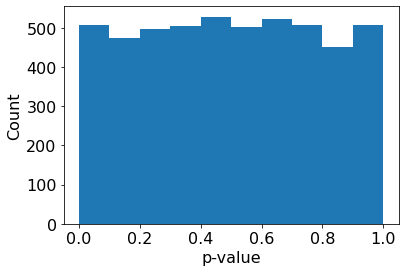

In [ ]:
# Your code here


---
### Part 3 (2 points)

Lets take a closer look at those p-values.
*   Plot `pvals` versus `tstats`.  Make a scatter plot where every data point is indicated by a black dot.
*   Repeat this plot on a second axis, but use `semilogy` instead of `plot` to produce a plot with a logarithmic y-axis.


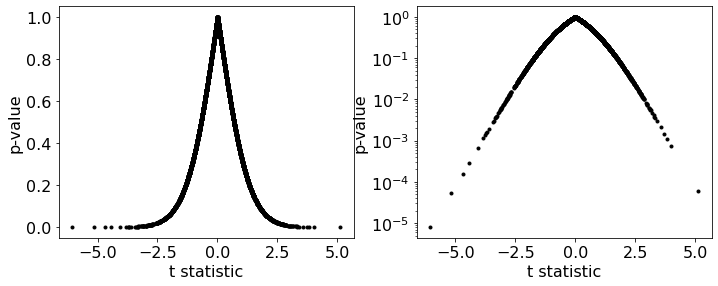

In [ ]:
# Your code here


Here, you should see that samples with means more different than 0 are associated with smaller p-values.  

The p-value represents the probability of your data having been observed under the null hypothesis of the test.  In this case, the null hypothesis is that the data were drawn from a distribution with mean 0.

Samples with means near zero are likely to have been drawn from a zero-mean distribution.  Samples with means more different than zero are less likely to be observed under the null hypothesis and have smaller p-values.

---
### Part 4 (2 points)

How often are particular p-values obtained by chance?

*   Calculate the proportion of entries in `pvals` less than 0.05.


In [ ]:
# Your code here


The proportion of pvals less than 0.05 is x.xx


You should fine that p-values less than 0.05 are obtained about 5% of the time.

Here, we know the null hypothesis - that our data were randomly selected from a zero-mean distribution - is true.  We expect small (less than 0.05)  p-values relatively rarely (5% of the time).  

**The p-value is the probability of observing a result as extreme or more extreme under the assumption that the null hypothesis is true.**

For example, a p-value of 0.05 indicates that 5% of the time we expect to observe a sample mean at least that different from the hypothesized mean of zero.  A p-value of 0.001 would indicate a very rare event - one that happens with 1/1000 odds - under the assumptions of the null hypothesis.

Low p-values indicate that the null hypothesis may not be correct.


### Part 5 (2 points)

Let's examine other variations of the t-test.

*   Repeat **Part 2**, but instead use `stats.ttest_1samp` to test whether each random sample has a mean less than zero by setting `alternative='less'`. This is called a *left-tailed test* because we are testing whether our test statistic lies in the left tail of the null distribution.
*   Repeat **Part 2** and test whether the mean of each random sample is greater than zero (right-tailed test). This is called a *right-tailed test*.
*   Plot `pvals` versus `tstats` as in **Part 3** in each case using `semilogy`.  Plot them on the same axes in different colors with an appropriate legend.

See the lecture notes on [One- vs. Two-tailed tests](https://depasquale-lab.github.io/BE559/lectures/Lecture1.5.html#one-vs-two-tailed-tests) for choosing the tail of a test.


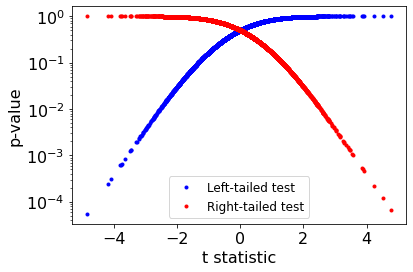

In [ ]:
# Your code here


In all cases, the p-value tells you the probability of observing an outcome under the assumption that the null hypothesis is true.  

 1-p is the probability of the opposite outcome.  Here,the **null hypotheses** are:

*   Two-sided test:  The sample was drawn from a distribution with **mean 0**.
*   Left-tailed test: The sample was drawn from a distribution with **mean 0 or greater**
*   Right-tailed test: The sample was drawn from a distribtuion with **mean 0 or less**.


### Part 6 (2 points)

Repeat **Parts 2-4**, but compare your data to a distribution with mean 0.5 (instead of zero) using the same procedure

The proportion of pvals less than 0.05 is x.xx
The proportion of pvals greater than 0.95 is x.xx


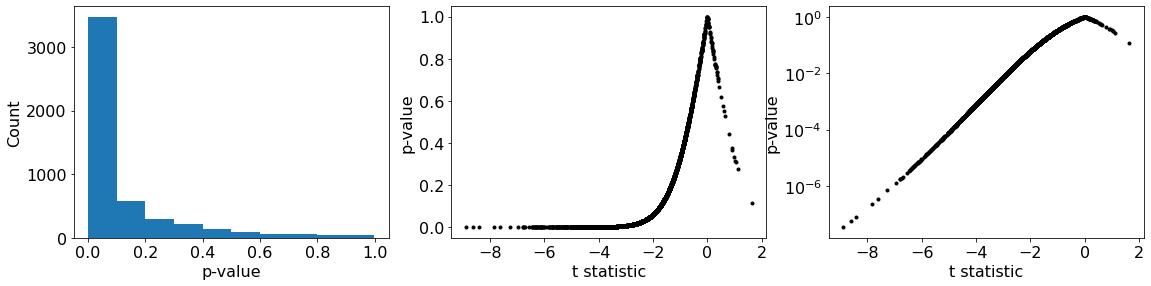

In [ ]:
# Your code here


In many instances, we calculate a p-value < 0.05, which indicates that the random sample was likely drawn from a distribution with a **mean different than 0**, as expected.

**But not always!** Sometimes we still select samples with associated p-values that are large, indicating that the null hypothesis cannot be rejected.  This indicates a **Type II error**  - failing to reject a false null hypothesis.  This is also called a **false negative**.

The type II erorr rate is closely related to the **statistical power** of a test - its ability (or inability) to correctly reject a null hypothesis when an alternative hypothesis is actually true.

We will examine statistical power a little more below.

### Part 7 (2 points)

*  Repeat **Part 6** but run a left-tailed t-test for each sample instead of a two sided test.  
*  Calculate the proportion of samples with associated p-values less than 0.05.
*  Compare this proportion to the proportion of p-values less than 0.05 when you used the two-sided test

In [ ]:
# Your code here


Left-tailed test: The proportion of pvals less than 0.05 is x.xx
Two-sided test: The proportion of pvals less than 0.05 is x.xx


Here, you should find a larger proportion of p-values less than  0.05 using the left-tailed test.


<font color='red'>**SHORT ANSWER (2 points):** Explain why the left-tailed test yields a p-value less than 0.05 (correctly rejects the null hypothesis) more frequently than the two-sided test in terms of the area under the probability density function of the t-statistic.</font>

### Part 8 (2 points)

Next, let's examine how stastical power changes as a function of sample size.


*   Run the same experiment as above with several variations.  Create a standard normal distribution and draw samples of size 4, 8, 16, 32, 64, 128, and 256.
*   Use a t-test  (`stats.ttest_1samp`) to test two null hypotheses: (1) that the data were drawn from a distribution with mean 0.5 and (2) that the data were drawn from a distribution with mean 0.25.
*   Repeat the steps above 500 times (you will need to use two nested `for` loops).
*   For each case, calculate the proportion of p-values less than 0.05.
*   Plot the proportion of p-values less than 0.05 vs. the sample size (true positive rate) with a logarithmic x-axis.
*  On the same axes, plot the false negative rate.
*  Choose iine styles that ensure the lines are easily distinguishable





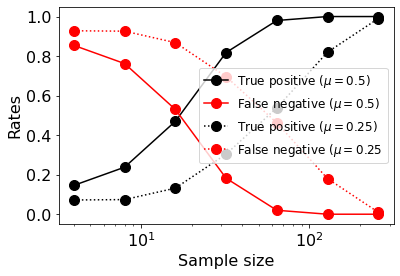

In [ ]:
# Your code here


Here, you should see that the true positive rate increases and the false negative rate decrease as the sample size increases.  

In this example, we are drawing samples from a mean-zero distribution and testing the hypothesis that the were drawn from distributions with mean 0.25 and mean 0.5.  In all cases, the null hypothesis is false.  We are more likely to reject the null hypothesis as the sample size increases (and our sample mean converges to the population mean) and as the effect size (difference between the actual population mean and the hypothesized population mean) increases.

Increasing sample size and/or effect size increases **statistical power**, the probability of correctly rejecting an incorrect null hypothesis (black lines above).



---



Thus far, we have examined one-sample t-tests, where we attempt to determine whether one sample of data was drawn from a distribution with a hypothesized mean.

Next, we will examine a **two-sample test**, where we will compare two samples of data and determine whether they were likely drawn from the same distribution.  There are several flavors of the two-sample t-test.  

We'll start with the simplest version, when the size of each sample is the same, and when we draw the two samples from populations that we assume to have the same (or similar) standard deviations.  In this case the test statistic (still called t) is:

${\displaystyle t={\frac {{\bar {X}}_{1}-{\bar {X}}_{2}}{s_{p}{\sqrt {\frac {2}{n}}}}}}$

Where

${\displaystyle s_{p}={\sqrt {\frac {s_{X_{1}}^{2}+s_{X_{2}}^{2}}{2}}}}$

and $s_{X_{1}}^{2}$, $s_{X_{2}}^{2}$ are the unbiased (divide by $n-1$ rather than $n$) estimates of the sample variances.

Our test statistic, *t*, still follows the same t distribution we examined in *Homework 1.2*.

When the two samples have different sizes, or different variances, the analytical expression for t becomes a bit more complex.


### Part 9 (2 points)

Here, we will only calculate a two-sample t-test using `scipy.stats`, although we could use the analytical expressions above (along with the expression for the PDF of the t distribution) to determine p-values directly if we so chose.

*  Draw 20 samples from a normal distribution with mean 0 and standard deviation 1 (Sample 1) and an additional 20 samples from a distribution with mean 0.5 and standard deviation 1 (Sample 2).
*  Use `scipy.stats.ttest_ind` to determine the probability that these samples were drawn from distributions with the same mean (the p-value for a two-sided test).
*  In addition, use `scipy.stats.ttest_1samp` to test whether Sample 1 was drawn from a distribution with mean 0.5 using a two-sided test.  Record the p-value for this test as well.
*  Repeat these steps 5000 times.
*  For each case, calculate the proportion of p-values less than 0.05.

See the lecture notes on [Variation: two-sample t-test (equal variances)](https://depasquale-lab.github.io/BE559/lectures/Lecture1.4.html#variation-two-sample-t-test-equal-variances) for the two-sample test.


In [ ]:
# Your code here


<font color='red'>**SHORT ANSWER (2 points):** Which test has greater statistical power?  Explain why. When would you use one test versus the other?</font>

### Part 10 (2 points)

In **Part 9** we examined a two-sample t-test using `scipy.stats.ttest_ind`.  There, 'ind' refers to a test of independent measurements.  That is, selecting a particular value in Sample 1 does not affect the values expected in Sample 2.

Next, we will examine paired samples and the associated paired t-test.  

For example, suppose we measure how long it takes 20 subjects to run a 5K race, subject them to a training regimine, and then measure how long it takes them to run a second 5K to determine if the training regimine reduces their 5K time.  

In this case, the samples are paired.  Exactly one measurement in Sample 1 and one measurement in Sample 2 correspond to each subject. Each person's first 5K time might tell us something about what to expect from their second 5K time.  We do not have two independent samples from the population of 5K times in this case.

Let's simulate this scenario and visualize the experiment using some new kinds of plots.
*   Load the datafile located at the following URL using `np.genfromtxt` into a variable called `raceData`:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework1/RaceData.csv

*   Create variables called `race1` and `race2` from the first and second columns of `raceData`.
*   Compare these two datasets with a boxplot.
*   Use `scipy.stats.ttest_ind` to calculate the probability that these two datasets were drawn from populations with the same mean.
*   Plot a scatterplot of `race2` vs. `race1`.  You should see that these two samples are  clearly correlated and, thus, not independent.  Include a dotted line indicating where y=x.
*   Display the paired data with lines connecting paired data points (as shown below).   

See the lecture notes on [Paired t-test (repeated measures)](https://depasquale-lab.github.io/BE559/lectures/Lecture1.4.html#paired-t-test-repeated-measures) for when and why to pair measurements.


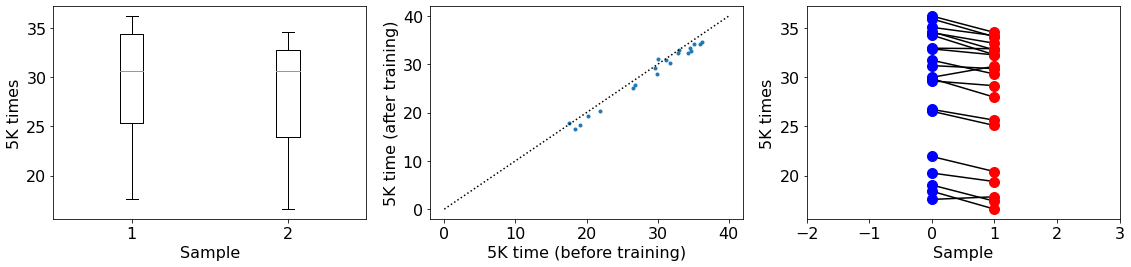

In [ ]:
# Your code here


Here, from the boxplots, you should see that the distributions of the data are quite similar.  In the second and third plots, however, you should see a systematic change in the paired measurements in the first and second samples.

How do we test whether the training regimine had the desired effect on 5K times?  We'll compare two kinds of tests below

### Part 11 (2 points)

*   Apply the upaired two-sample t-test as in **Part 8**.  Report the p-value.
*   Apply a **paired t-test** (`stats.ttest_rel`) to these two samples as well.  Report this p-value as well.

🚩 **Common mistake:** A paired test assumes entry *i* of Sample 1 and entry *i* of Sample 2 belong to the same subject. If you sort or shuffle one array independently, `stats.ttest_rel` still returns a p-value but it is meaningless.


In [ ]:
# Your code here


Unpaired t-test p-value = x.xx
Unpaired t-test p-value = x.xx


These two tests should yield very different results.  Why is this?

While ostensibly a two-sample test, the paired t-test is really a test of the differences between the paired samples (i.e. the values of `race2-race1`).

  While `race1` and `race2` have similar means and variances, the differences have a mean that can be confidently differentiated from zero.

We can see this clearly by plotting a histogram of the differences, the values of `race2-race1`.

### Part 12 (2 points)

*   Plot a histogram of the values of `race2-race1`, the changes in each individuals 5K time.


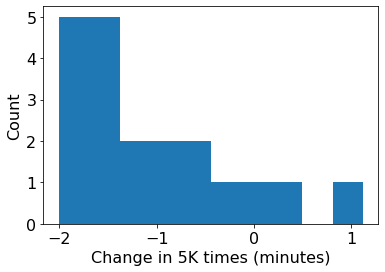

In [ ]:
# Your code here


The values of `race2-race1` appear unlikely to have been drawn from a distribution with a mean different than zero, indicating a change in race times, even though the values in `race1` and `race2` follow similar distributions.

Here, the paired t-test is really a one-sample t-test where we are comparing the difference in values between `race1` and `race2` with a hypothesized mean of zero.  That is, the null hypothsis is that the values in `race2-race` are drawn from a distribution that is zero mean.  

## Homework 1.4 (18 points)

**Learning objectives:**

In this assignment, we will continue our exploration  of statistics and hypothesis testing.  We will explore:

*   Non-parametric statistics
*   The bootstrap


---

### Part 1
Load the same libraries that we used in *Homeworks 1.1 and 1.2*. 

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `scipy.stats` (as `stats`)

Now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---

Let's examine the statistical power of parametric and non-parametric statistical tests.  

First, we will compare the 1-sample t-test (parametric) and the sign test (nonparametric).


---
### Part 2 (2 points)

*   Draw a random sample from a standard normal distribution of size `Nsamp = 16`.
*   Use a t-test to determine the p-value for a two-sided test of the null hypothesis that the data were drawn from a population with a hypothesized mean `HypMean = 0.5`.

*   Repeat this procedure 500 times.
*   Find the true positive rate - the proportion of the 500 repetitions in which the null hypothesis (which we know to be **false**) was correctly rejected at an $\alpha$ level of 0.05.



In [ ]:
# Your code here


True positive rate: x.xxx (effect size 0.5)


---
### Part 3 (2 points)

Repeat **Part 2**, but set `HypMean` = 0

*   Find the false positive rate - the proportion of the 500 repetitions in which the null hypothesis (which we know to be **correct**) was incorrectly rejected at an $\alpha$ level of 0.05.


In [ ]:
# Your code here


False positive rate: x.xxx (effect size 0.0)


---
### Part 4 (2 points)

*   Use similar procedures to find the power (true positive rate) for effect sizes of 0.5 and 1.0 (`HypMean=0.5, 1.0`) as well as the false positive rate (`HypMean=0`) of the 1-sample t-test when `Nsamp` is equal to 4, 8, 16, 32, and 64 at an $\alpha$ level of 0.05.
*   This can be accomplished, for example with three nested `for` loops.
*   Plot the results as shown below using `semilogx`.



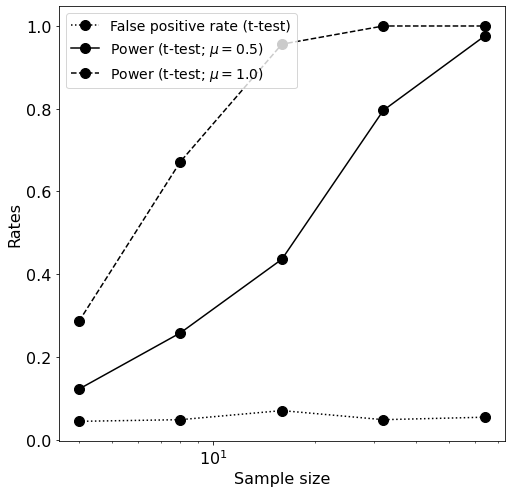

In [ ]:
# Your code here


---
### Part 5 (2 points)

Repeat **Part 4**, but use a sign test instead of a t-test.

To perform a sign test:
*   Determine the number of values in the random sample greater than `HypMean`.  Call this number `numPositives`.
*   Use a binomial test (`stats.binomtest`) to determine the probability of observing a value of numPositives at least as extreme as the observed number (a two-tailed test) under the assumption that the probability that each sample is greater than `HypMean` is 0.5.
*   Find the p-value for this test.  

NOTE:  the output of `stats.binomtest` is a structured a little differently than other statistical tests we have used so far.  You may have to look up the documation for `stats.binomtest` to figure out how to access the p-value for the test.


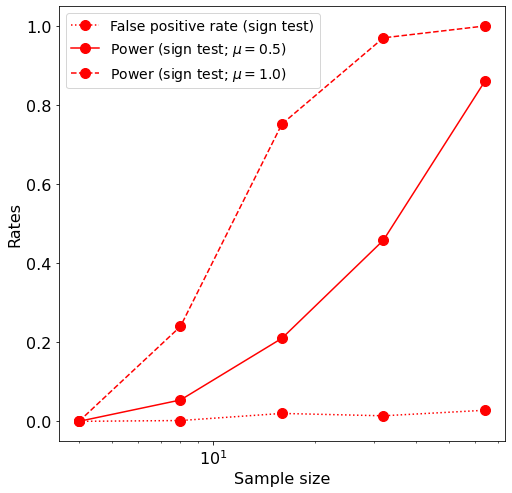

In [ ]:
# Your code here


---
### Part 6 (2 points)
*   Plot the results of **Parts 4 and 5** on a common axis
*   Make the plot size large using a command like `fig.set_size_inches(10, 10)

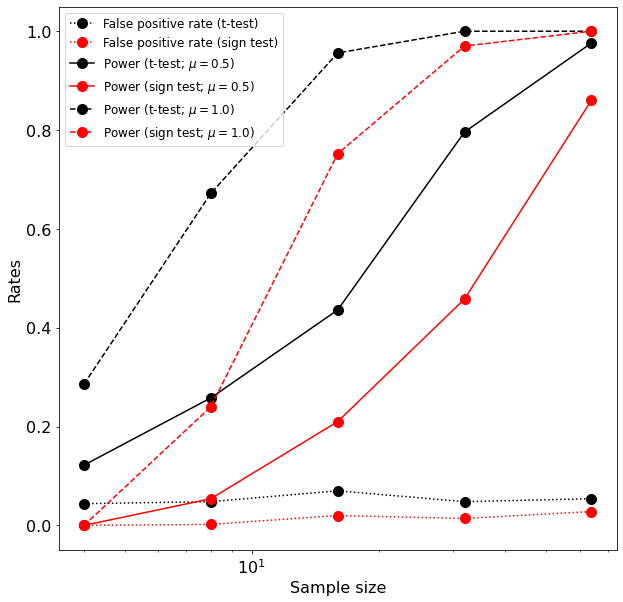

In [ ]:
# Your code here


---
### Part 7 (2 points)

Finally, we'll explore the bootstrap.

*   First, create a population with an unusual distribution.  Use the following code to create the variable `population`:


```
np.random.seed(seed=3)

Nvals1 = 8000
Nvals2 = 2000

vals1 = stats.norm.rvs(loc=-3, scale=1, size=Nvals1)
vals2 = stats.norm.rvs(loc=3, scale=1, size=Nvals2)
population = np.concatenate((vals1, vals2), axis=0)
```

The first command (`np.random.seed(seed=3)`) ensures that the same random numbers are generated each time the code runs.  The number `3` is a bit arbitrary.  We just want to set the seed to the same number each time the code is run.

*   Plot a histogram of values in the population.  Use 50 bins and set `density=True`.





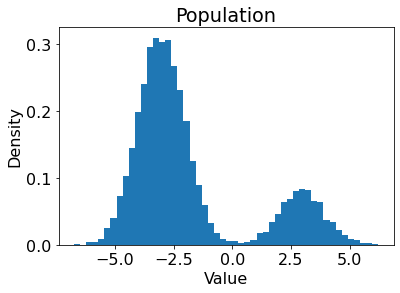

In [ ]:
# Your code here


---
### Part 8 (2 points)

Consider a statistic:  the standard deviation of samples of size `Nsamp=16` drawn from `population`.  What is the sampling distribution of this statistic?

Estimate the sampling distribution using a Monte Carlo Simulation.  
*   Set the random seed to 3 (`np.random.seed(seed=3)`)

*   Draw 16 samples randomly from the population (with replacement) using `np.random.choice`. 

*   Find the standard deviation of the sample.

*   Repeat this procedure 10,000 times and store the sample standard deviations in a variable called `sdDistribution`.

*   Plot a histogram of `sdDistribution` as above.




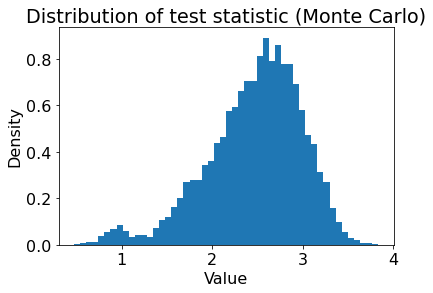

In [ ]:
# Your code here


---
### Part 9 (2 points)

Now, let's try to bootstrap the same distribution. 
*   Set the random seed to 3 (`np.random.seed(seed=3)`).
*   Draw only a **single** sample of size `Nsamp=16` from `population`.  Call it `observedData`.

Suppose we don’t have access to `population` and, instead, all we have is `observedData`. We can use the bootstrap method with `observedData` to estimate the distribution of the test statistic.  To do this, do the following:

*    Draw a random sample of size `Nsamp=16` from `observedData`.  Ensure that you sample **with replacement** or else the sample will be the same as `observedData`.  Calculate the standard deviation of this random sample.
*    Resample `observedData` (by repeating the previous step) 10,000 times and calculate the standard deviation each time.  Store the standard deviation values in a variable called `bootDistribution`.  
*    Plot a histogram of both `sdDistribution` and `bootDistribution` in the same way as above.  Set `alpha=0.3` so that the histograms are partially transparent.



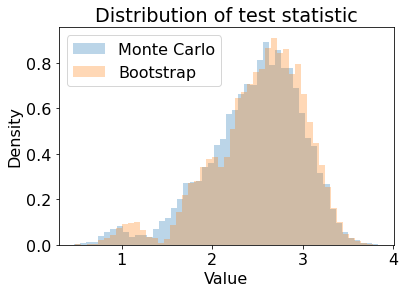

In [ ]:
# Your code here


---
### Part 10 (2 points)

Find the 5-95% confidence interval on the test statistic (the sample standard deviation) using the Monte Carlo simulution and the bootstrapped distribution.

*   Use `np.percentile` to find the 5th and 95th percentile of `sdDistribution`.
*   Use `np.percentile` to find the 5th and 95th percentile of `bootDistribution`.

In [ ]:
# Your code here


5 - 95% confidence interval:  x.xxx - x.xxx (Monte Carlo)
5 - 95% confidence interval:  x.xxx - x.xxx (bootstrap)
